# Activity 2: Simple House Price Prediction

**Unit II – Supervised Learning: Regression**  
**Objective:** Build a Simple Linear Regression model to predict a continuous house-price value and evaluate its performance.

This notebook uses the USA Housing dataset. It selects **Average Area Income** as the single input feature and **Price** as the continuous target. The notebook retains the executed code outputs and plots from the experiment.


In [37]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


## Step 1 – Select and understand the dataset

**Dataset:** USA Housing  
**Source:** [USA Housing CSV](https://raw.githubusercontent.com/VALENCEML/eBOOK/main/EN/08/USA_Housing.csv)  
**Description:** The dataset contains 5,000 house/property records and seven columns, including area income, house age, rooms, bedrooms, area population, price, and address.

The notebook first looks for `USA_Housing.csv` in the project folder. If the file is not present (for example, in a fresh Colab session), it reads the same CSV from the source URL.


In [38]:
from pathlib import Path

# Load the CSV from the project folder when available.
# If it is not present (for example, in a fresh Colab session), load it from the source URL.
dataset_path = Path("USA_Housing.csv")
dataset_url = "https://raw.githubusercontent.com/VALENCEML/eBOOK/main/EN/08/USA_Housing.csv"

if dataset_path.exists():
    df = pd.read_csv(dataset_path)
    print("Dataset loaded from local file:", dataset_path)
else:
    df = pd.read_csv(dataset_url)
    print("Local CSV not found. Dataset loaded from the source URL.")

# Display first five records
display(df.head())


Dataset loaded from local file: USA_Housing.csv


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\r\nLaurabury, NE 37..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\r\nLake Kathleen, ..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\r\nDanieltown, WI 064..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\r\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\r\nFPO AE 09386


## Step 2 – Load and inspect the data

The first records, dataset dimensions, column names, data types, statistical summary, missing-value counts, and duplicate count are inspected below. In the original run, the dataset contained **5,000 rows and 7 columns**, with six numerical columns and one text address column. The initial inspection found **no missing values and no duplicate rows**.


In [39]:

# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (5000, 7)

Column Names:
['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB

Statistical Summary:


,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06



Missing Values:
Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

Duplicate Records: 0


### Data cleaning

Duplicate records are removed, rows missing the selected feature or target are dropped, and non-positive target prices are excluded. In the recorded run, no rows were removed because the selected columns had no missing values, there were no duplicates, and all target prices were positive.


In [40]:

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print("Missing values before handling:")
print(df.isnull().sum())

# Remove rows with missing values in selected columns
df = df.dropna(subset=["Avg. Area Income", "Price"])

# Remove invalid non-positive prices
df = df[df["Price"] > 0]

print("\nDataset shape after cleaning:", df.shape)
print("Missing values after handling:")
print(df[["Avg. Area Income", "Price"]].isnull().sum())


Missing values before handling:
Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

Dataset shape after cleaning: (5000, 7)
Missing values after handling:
Avg. Area Income    0
Price               0
dtype: int64


## Step 3 – Select input feature and target

- **Input feature (X):** `Avg. Area Income`
- **Target (y):** `Price`

Average area income is selected because area income may be associated with housing demand and purchasing power. `Address` is not used as a predictive feature because it is an identifier-like text field, not a meaningful numerical predictor for this simple model.


In [41]:

# Input feature (X)
X = df[["Avg. Area Income"]]

# Target variable (y)
y = df["Price"]

print("Input Feature: Avg. Area Income")
print("Target Variable: Price")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


Input Feature: Avg. Area Income
Target Variable: Price

X Shape: (5000, 1)
y Shape: (5000,)


## Step 4 – Visualize the relationship

The scatter plot places average area income on the horizontal axis and actual house price on the vertical axis. Use the plotted pattern to describe the direction and strength of the visible association. A visible relationship does not, by itself, establish causation.


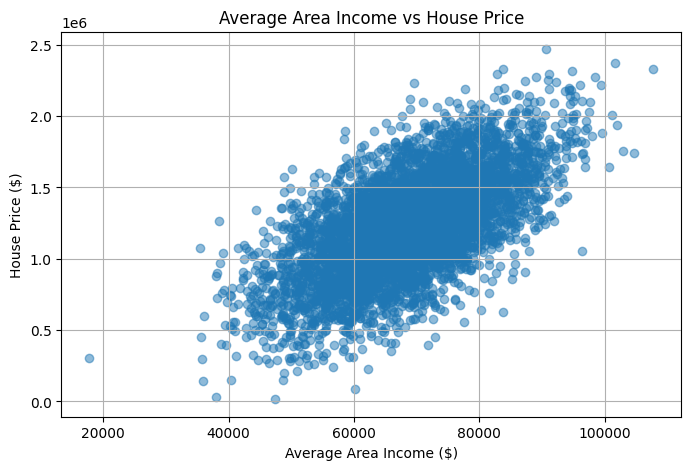

In [42]:

plt.figure(figsize=(8, 5))

plt.scatter(X["Avg. Area Income"], y, alpha=0.5)

plt.title("Average Area Income vs House Price")
plt.xlabel("Average Area Income ($)")
plt.ylabel("House Price ($)")

plt.grid(True)
plt.show()


## Step 5 – Split the dataset

The data is split into **80% training** and **20% testing** observations using `random_state=42`. The training set is used to learn model parameters; the test set is held out for evaluation on unseen observations. The test set is not used to train the model.


In [43]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_test))


Training observations: 4000
Testing observations: 1000
Total observations: 5000


## Step 6 – Train Simple Linear Regression

A Scikit-learn `LinearRegression` model is fitted using the training observations. For a single-feature model, the fitted equation is:

\[\hat{y} = mx + c\]

where `m` is the learned coefficient (slope), `c` is the intercept, `x` is average area income, and `ŷ` is predicted house price. The slope estimates the change in predicted price for a one-unit increase in area income. The intercept is the model's predicted price at zero income; zero is outside the useful data range, so the intercept has limited practical meaning here.


In [44]:

model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display coefficient and intercept
print("Coefficient (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)


Coefficient (Slope): 21.208906292657513
Intercept: -225053.70287170145


## Step 7 – Generate test-set predictions

Predictions are generated only for `X_test`. The table below compares a sample of actual and predicted prices from the held-out test set. Differences between the two columns are prediction errors.


In [45]:

y_pred = model.predict(X_test)

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))


Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,1.339096e+06,1.087939e+06
1,1.251794e+06,9.872517e+05
2,1.340095e+06,1.263616e+06
3,1.431508e+06,1.245080e+06
4,1.042374e+06,1.323016e+06
5,1.555321e+06,1.442687e+06
6,1.250882e+06,9.078950e+05
7,1.039381e+06,1.044659e+06
8,8.324752e+05,8.724630e+05
9,1.420648e+06,1.465078e+06


## Step 8 – Evaluate model performance

The notebook calculates four regression metrics:

- **MAE:** mean absolute difference between actual and predicted prices.
- **MSE:** mean squared prediction error; larger errors receive greater weight because errors are squared.
- **RMSE:** square root of MSE, expressed in the target's units (dollars).
- **R²:** compares the model with a baseline that predicts the mean target value. Test-set R² can be negative when the model performs worse than that baseline.

Interpret the values in the context of house prices rather than treating the metrics as scores without units or meaning.


In [46]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Metrics")
print("------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)


Model Evaluation Metrics
------------------------
Mean Absolute Error (MAE): 216826.35309989064
Mean Squared Error (MSE): 74194887058.66
Root Mean Squared Error (RMSE): 272387.38417676394
R2 Score: 0.39694865192619766


## Step 9 – Actual versus predicted visualization

The dashed diagonal represents perfect predictions (`predicted price = actual price`). Points closer to this line indicate smaller errors; points farther away indicate larger errors. The spread around the line helps assess how well the single-feature model predicts the held-out observations.


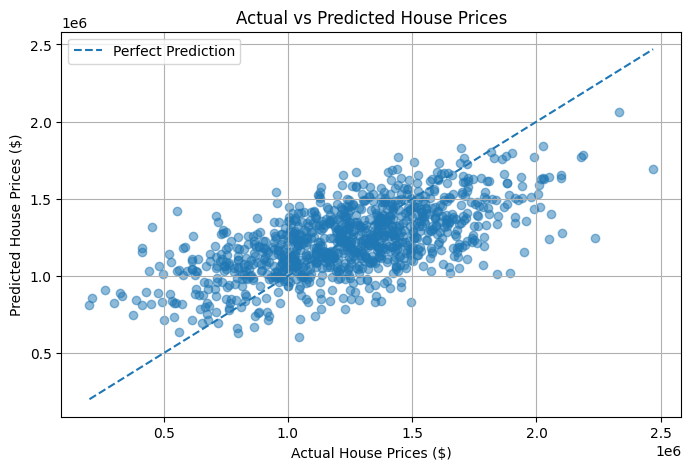

In [47]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.legend()
plt.grid(True)

plt.show()

## Step 10 – Predict a new example and conclude

A new input is chosen using the median average-area income from the training data, keeping the example within the range represented in the training set. The fitted model then predicts its house price.


In [48]:

# Select a new input value using training data range
new_income = X_train["Avg. Area Income"].median()

new_house = pd.DataFrame({
    "Avg. Area Income": [new_income]
})

predicted_price = model.predict(new_house)

print("New Average Area Income:", new_income)
print("Predicted House Price: $", round(predicted_price[0], 2))


New Average Area Income: 68926.42146781259
Predicted House Price: $ 1236800.31


### Conclusion

This activity used Simple Linear Regression to predict house prices from average area income. The data was inspected and cleaned, divided into training and testing sets, and used to train a model. Test predictions were evaluated using MAE, MSE, RMSE, and R², and both the feature relationship and actual-versus-predicted results were visualized.

The model's test R² is approximately **0.397**, so average area income alone explains about **39.7%** of the variation in test-set house prices. The MAE is approximately **$216,826**, indicating that prediction errors are substantial relative to typical house prices in this dataset. The example prediction is approximately **$1,236,800.31** for an average area income of **$68,926.42**.

House prices may also depend on location, property size, age, number of rooms, facilities, and other factors. A one-feature linear model cannot capture all these influences. A future extension could compare this baseline with a multiple linear regression model using additional relevant features.
